# Лабораторная работа 1. Линейная регрессия

Выполнил Колосов Егор Евгеньевич, группа М8О-312БВ-24

Задача — предсказать кредитный риск `RiskScore` по данным заёмщиков. Основная метрика — MSE,
ориентир на Kaggle — меньше 19. Кроме итоговой модели, проверяю собственные реализации
нормализации, метрик, линейной регрессии и кросс-валидации.

Исходные файлы находятся в папке `data`. Ячейки запускаются по порядку;
в конце получается `submission.csv`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize

import sklearn
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import Ridge as SkRidge, Lasso as SkLasso, ElasticNet as SkElasticNet, SGDRegressor as SkSGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import KFold as SkKFold, LeaveOneOut as SkLeaveOneOut
from sklearn.preprocessing import StandardScaler as SkStandardScaler, MinMaxScaler as SkMinMaxScaler

SEED = 42
TARGET = 'RiskScore'
DATA_DIR = Path('data')
OUT_DIR = Path('.')
plt.rcParams['figure.dpi'] = 110

print(f'Python: {sys.version.split()[0]} | numpy: {np.__version__} | pandas: {pd.__version__} | '
      f'matplotlib: {matplotlib.__version__} | scipy: {scipy.__version__} | sklearn: {sklearn.__version__}')
for filename in ['train.csv','test.csv','ex.csv']:
    if not (DATA_DIR/filename).is_file():
        raise FileNotFoundError(f'Не найден {DATA_DIR/filename}; положите исходные CSV в DATA_DIR')


Python: 3.13.15 | numpy: 2.5.4 | pandas: 3.1.1 | matplotlib: 3.11.2 | scipy: 1.18.1 | sklearn: 1.9.1


## 1. Загрузка и очистка данных

Сначала смотрю размеры таблиц, типы столбцов, пропуски и повторы. Проверяю, что набор
признаков в train и test совпадает, а идентификаторы идут в том же порядке, что и в `ex.csv`.

В train есть пустые строки, дубликаты и значения-заглушки `RiskScore`: `-9999999` и `10000000`.
Ещё у части строк не заполнены сразу девять признаков. Эти строки удаляю: восстанавливать
такой большой блок пропусков было бы ненадёжно. В test пропусков нет.


In [2]:
train_raw = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'ex.csv')

assert [c for c in train_raw.columns if c != TARGET] == [c for c in test.columns if c != 'ID']
assert test['ID'].equals(sample['ID'])

print(f'train_raw: {train_raw.shape}, test: {test.shape}, ex: {sample.shape}')
print('Признаки train/test и ID test/ex совпадают.')

overview = pd.DataFrame({
    'dtype': train_raw.dtypes.astype(str),
    'missing_train': train_raw.isna().sum(),
    'missing_test': test.isna().sum().reindex(train_raw.columns).fillna(0).astype(int),
    'nunique_train': train_raw.nunique(),
})
print(overview.to_string())

empty_rows = int(train_raw.isna().all(axis=1).sum())
dup_rows = int(train_raw.dropna(how='all').duplicated().sum())
outlier_rows = int((~train_raw[TARGET].dropna().between(0, 100)).sum())
print(f'Пустых строк: {empty_rows} | дубликатов: {dup_rows} | выбросов RiskScore: {outlier_rows}')
print('Пропусков в test:', int(test.isna().sum().sum()), '| дубликатов в test:', int(test.duplicated().sum()))

def clean_train(df):
    out = df.dropna(how='all').drop_duplicates()
    out = out[out[TARGET].between(0, 100)]
    return out.dropna().reset_index(drop=True)

train = clean_train(train_raw)
y_all = train[TARGET].to_numpy(dtype=float)

CAT_COLS = ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']
NUM_COLS = [c for c in train.select_dtypes(include=np.number).columns if c != TARGET]

print(f'После очистки train: {train.shape}, RiskScore min={y_all.min():.2f}, max={y_all.max():.2f}, mean={y_all.mean():.2f}')
print(train[NUM_COLS + [TARGET]].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2).to_string())
dates = pd.to_datetime(train['ApplicationDate'],errors='raise')
year = dates.dt.year
print(f'Даты заявок: {dates.min().date()} — {dates.max().date()}, уникальных дат: {dates.nunique()}')
print('Корреляция года заявки с RiskScore:',round(float(year.corr(train[TARGET])),4))
print('Доля строк с MonthlyIncome = AnnualIncome / 12:',
      round(float(np.isclose(train.MonthlyIncome,train.AnnualIncome/12).mean()),4))


train_raw: (11017, 35), test: (5000, 35), ex: (5000, 2)
Признаки train/test и ID test/ex совпадают.
                              dtype  missing_train  missing_test  nunique_train
ApplicationDate                 str            530             0          10000
Age                         float64            530             0             63
AnnualIncome                float64            530             0           5602
CreditScore                 float64           1031             0            548
LoanAmount                  float64           1031             0           8720
LoanDuration                float64            530             0             10
MaritalStatus                   str            530             0              4
NumberOfDependents          float64            530             0              7
HomeOwnershipStatus             str            530             0              4
MonthlyDebtPayments         float64           1031             0           1736
CreditCardUtilizatio

## 2. Разведочный анализ данных


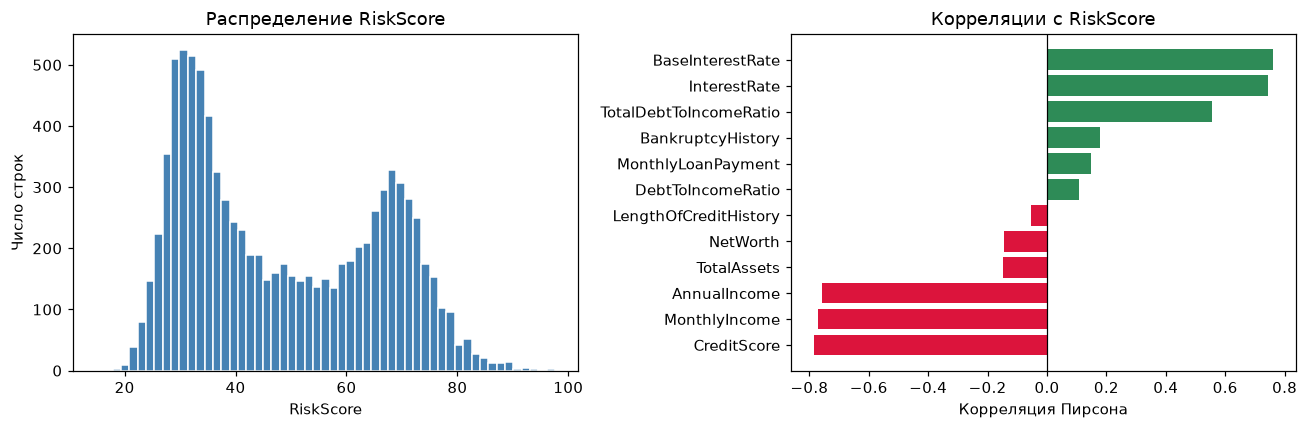

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y_all, bins=55, color='steelblue', edgecolor='white')
ax[0].set(title='Распределение RiskScore', xlabel='RiskScore', ylabel='Число строк')

corr_target = train[NUM_COLS + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
top_corr = pd.concat([corr_target.head(6), corr_target.tail(6)])
colors = ['crimson' if v < 0 else 'seagreen' for v in top_corr.values]
ax[1].barh(top_corr.index, top_corr.values, color=colors)
ax[1].axvline(0, color='black', linewidth=0.8)
ax[1].set(title='Корреляции с RiskScore', xlabel='Корреляция Пирсона')
plt.tight_layout()
plt.show()

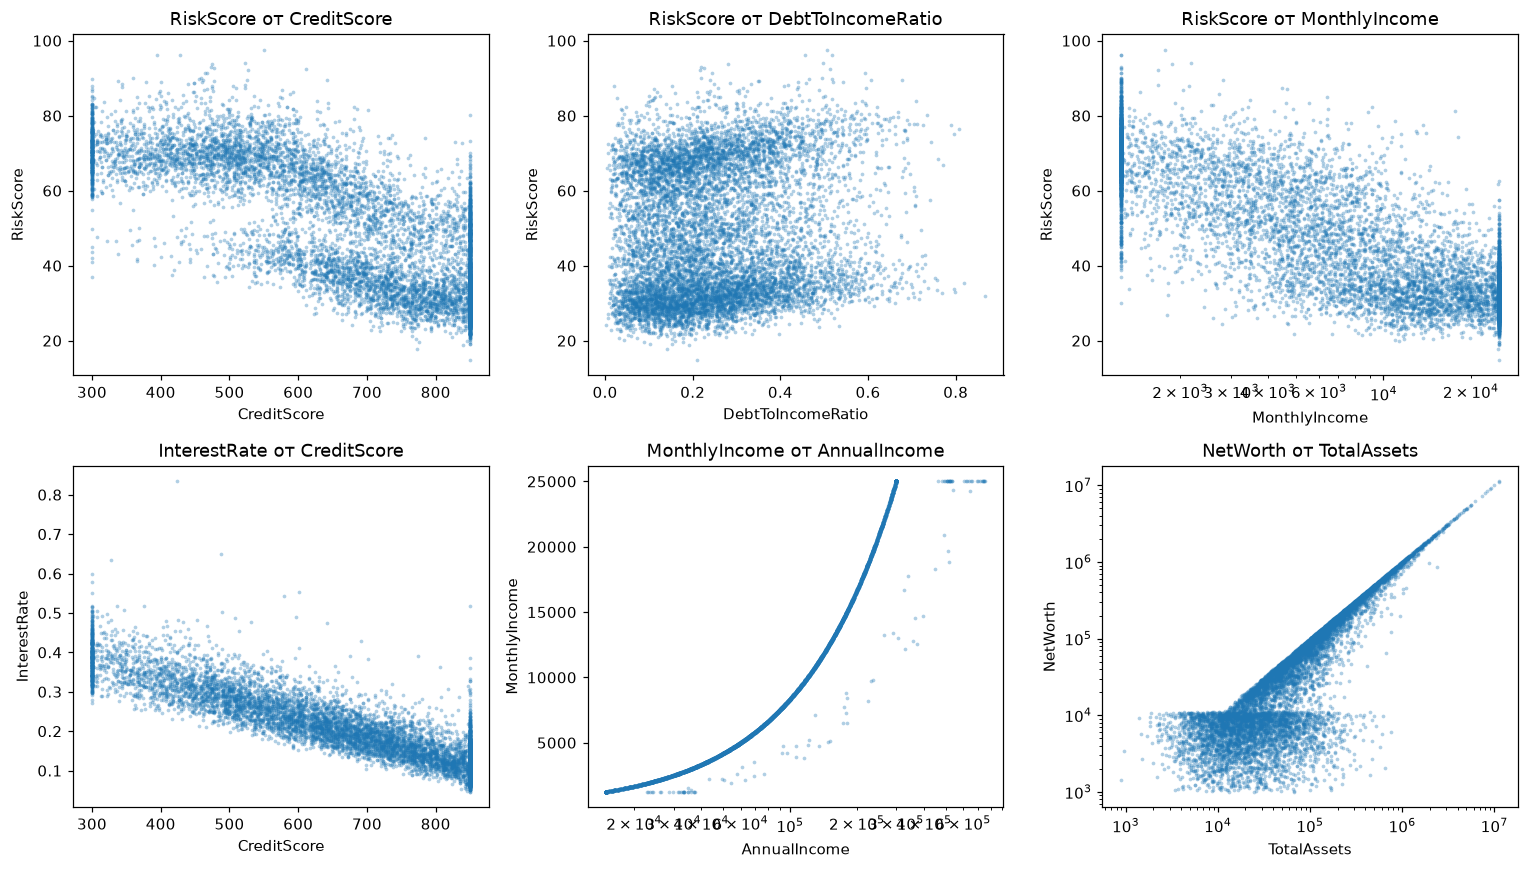

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
pairs = [
    ('CreditScore', TARGET),
    ('DebtToIncomeRatio', TARGET),
    ('MonthlyIncome', TARGET),
    ('CreditScore', 'InterestRate'),
    ('AnnualIncome', 'MonthlyIncome'),
    ('TotalAssets', 'NetWorth'),
]
for axis, (x_col, y_col) in zip(ax.ravel(), pairs):
    axis.scatter(train[x_col], train[y_col], s=6, alpha=0.35, linewidths=0)
    if x_col in ('MonthlyIncome', 'TotalAssets', 'AnnualIncome'):
        axis.set_xscale('log')
    if y_col == 'NetWorth':
        axis.set_yscale('log')
    axis.set(xlabel=x_col, ylabel=y_col, title=f'{y_col} от {x_col}')
plt.tight_layout()
plt.show()

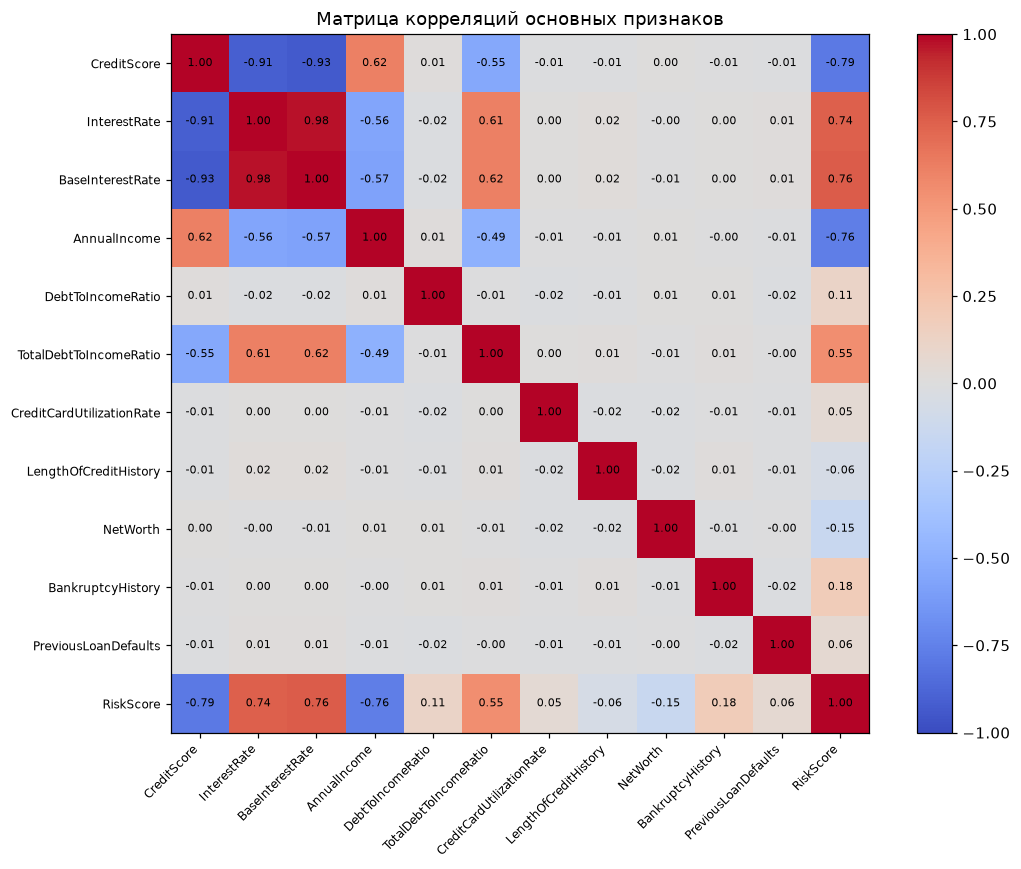

In [5]:
key_cols = ['CreditScore', 'InterestRate', 'BaseInterestRate', 'AnnualIncome', 'DebtToIncomeRatio',
            'TotalDebtToIncomeRatio', 'CreditCardUtilizationRate', 'LengthOfCreditHistory',
            'NetWorth', 'BankruptcyHistory', 'PreviousLoanDefaults', TARGET]
corr_mat = train[key_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_mat, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(key_cols)))
ax.set_yticks(range(len(key_cols)))
ax.set_xticklabels(key_cols, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(key_cols, fontsize=8)
for i in range(len(key_cols)):
    for j in range(len(key_cols)):
        ax.text(j, i, f'{corr_mat.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Матрица корреляций основных признаков')
plt.tight_layout()
plt.show()

На гистограмме `RiskScore` видны два пика — около 30 и 68. На графиках зависимости от
признаков тоже заметны два уровня риска. Это стало основанием проверить модель с двумя режимами.

Сильнее всего с целью связаны кредитный рейтинг, доход, процентная ставка и общая долговая
нагрузка. При этом низкая линейная корреляция ещё не означает, что признак бесполезен:
зависимость может быть пороговой.

Некоторые столбцы почти дублируют друг друга. Например, годовой и месячный доход тесно связаны,
хотя равенство `MonthlyIncome = AnnualIncome / 12` выполняется не для всех строк.
Поэтому дальше проверяю ранг матрицы и использую устойчивое решение МНК.

У даты проверил диапазон и связь года с целью. Календарные признаки в выбранную модель
не вошли. Оценка на случайных фолдах относится к этому разбиению данных; качество на будущих
периодах здесь отдельно не проверяется. `ID` нужен только для файла посылки.


## 3. Нормализация: z-score и min-max

Реализую оба преобразования:

$$z_j=\frac{x_j-\mu_j}{\sigma_j},\qquad
x_j^{\text{minmax}}=\frac{x_j-\min_j}{\max_j-\min_j}.$$

Среднее, стандартное отклонение и границы считаю на обучающей части. К валидации применяю
уже сохранённые параметры. Для стандартного отклонения использую `ddof=0`, как в `StandardScaler`.
У константного столбца заменяю нулевой делитель на 1. Ниже сверяю результат со sklearn
и отдельно проверяю этот случай.


In [6]:
class ZScoreScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0, ddof=0)
        self.scale_ = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class MinMaxNormalizer:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        span = X.max(axis=0) - self.min_
        self.span_ = np.where(span == 0, 1.0, span)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.span_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


X_num = train[NUM_COLS].to_numpy(dtype=float)
tr_demo, va_demo = np.arange(0, 7000), np.arange(7000, len(X_num))

z_scaler = ZScoreScaler().fit(X_num[tr_demo])
z_tr, z_va = z_scaler.transform(X_num[tr_demo]), z_scaler.transform(X_num[va_demo])
sk_z = SkStandardScaler().fit(X_num[tr_demo])
mm_scaler = MinMaxNormalizer().fit(X_num[tr_demo])
mm_tr, mm_va = mm_scaler.transform(X_num[tr_demo]), mm_scaler.transform(X_num[va_demo])
sk_mm = SkMinMaxScaler().fit(X_num[tr_demo])

print(f'Макс. отклонение ZScore на train: {np.max(np.abs(z_tr - sk_z.transform(X_num[tr_demo]))):.2e} | '
      f'на val: {np.max(np.abs(z_va - sk_z.transform(X_num[va_demo]))):.2e}')
print(f'Макс. отклонение MinMax на train: {np.max(np.abs(mm_tr - sk_mm.transform(X_num[tr_demo]))):.2e} | '
      f'на val: {np.max(np.abs(mm_va - sk_mm.transform(X_num[va_demo]))):.2e}')

const_col = np.array([[5.0, 1.0], [5.0, 3.0], [5.0, 5.0]])
assert np.allclose(ZScoreScaler().fit_transform(const_col)[:, 0], 0.0)
assert np.allclose(MinMaxNormalizer().fit_transform(const_col)[:, 0], 0.0)
print('Проверка константного столбца пройдена.')

Макс. отклонение ZScore на train: 0.00e+00 | на val: 0.00e+00
Макс. отклонение MinMax на train: 2.22e-16 | на val: 1.11e-16
Проверка константного столбца пройдена.


## 4. Метрики качества

Для оценки использую четыре метрики:

$$\mathrm{MSE}=\frac1n\sum_{i=1}^n(y_i-\hat y_i)^2,\qquad
\mathrm{MAE}=\frac1n\sum_{i=1}^n|y_i-\hat y_i|.$$

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad
\mathrm{MAPE}=\frac1n\sum_{i=1}^n\frac{|y_i-\hat y_i|}{\max(|y_i|,\varepsilon)}.$$

MAPE возвращаю долей: например, `0.07` означает 7%. Как и в sklearn, в знаменателе
использую машинный эпсилон. При нулевой или очень маленькой цели результат может стать
огромным, поэтому такой случай проверяю отдельно. Для одного наблюдения R² не определён:
функция возвращает `NaN`.

Сначала проверяю ответы на небольшом примере, затем сравниваю свои функции со sklearn.


In [7]:
def _check_1d_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.ndim != 1 or y_pred.ndim != 1 or y_true.shape != y_pred.shape:
        raise ValueError(f'Ожидались одномерные массивы одинаковой длины, получено {y_true.shape} и {y_pred.shape}')
    if len(y_true)==0 or not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
        raise ValueError('Нужны непустые конечные массивы')
    return y_true, y_pred


def mse(y_true, y_pred):
    y_true, y_pred = _check_1d_pair(y_true, y_pred)
    return float(np.mean((y_true - y_pred) ** 2))


def mae(y_true, y_pred):
    y_true, y_pred = _check_1d_pair(y_true, y_pred)
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    y_true, y_pred = _check_1d_pair(y_true, y_pred)
    if len(y_true) < 2:
        return float('nan')
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    if ss_tot == 0.0:
        return 1.0 if ss_res == 0.0 else 0.0
    return float(1.0 - ss_res / ss_tot)


def mape(y_true, y_pred):
    y_true, y_pred = _check_1d_pair(y_true, y_pred)
    eps = np.finfo(float).eps
    return float(np.mean(np.abs(y_true - y_pred) / np.maximum(np.abs(y_true), eps)))


def all_metrics(y_true, y_pred):
    return {
        'MSE': mse(y_true, y_pred),
        'MAE': mae(y_true, y_pred),
        'R2': r2(y_true, y_pred),
        'MAPE': mape(y_true, y_pred),
    }


yt_toy = np.array([2.0, 4.0, 5.0])
yp_toy = np.array([2.0, 5.0, 3.0])
assert np.isclose(mse(yt_toy, yp_toy), 5.0 / 3.0)
assert np.isclose(mae(yt_toy, yp_toy), 1.0)
assert np.isclose(r2(yt_toy, yp_toy), -1.0 / 14.0)
assert np.isclose(mape(yt_toy, yp_toy), 13.0 / 60.0)

rng = np.random.default_rng(SEED)
yt = y_all[:500]
yp = yt + rng.normal(0, 3.0, size=len(yt))
check_metrics = pd.DataFrame({
    'Своя': [mse(yt, yp), mae(yt, yp), r2(yt, yp), mape(yt, yp)],
    'sklearn': [
        mean_squared_error(yt, yp),
        mean_absolute_error(yt, yp),
        r2_score(yt, yp),
        mean_absolute_percentage_error(yt, yp),
    ],
}, index=['MSE', 'MAE', 'R2', 'MAPE'])
check_metrics['Разница'] = np.abs(check_metrics['Своя'] - check_metrics['sklearn'])
print(check_metrics.to_string())

assert np.isnan(r2([1.0], [1.0]))
assert np.isclose(r2([5.0, 5.0, 5.0], [5.0, 5.0, 5.0]), r2_score([5.0, 5.0, 5.0], [5.0, 5.0, 5.0]))
assert np.isclose(r2([5.0, 5.0, 5.0], [5.0, 6.0, 4.0]), r2_score([5.0, 5.0, 5.0], [5.0, 6.0, 4.0]))
assert np.isclose(mape([0.0, 2.0, 4.0], [0.5, 2.5, 3.5]), mean_absolute_percentage_error([0.0, 2.0, 4.0], [0.5, 2.5, 3.5]))
print('Ответы на ручном примере и в особых случаях совпали с ожидаемыми.')

          Своя   sklearn  Разница
MSE   8.278226  8.278226      0.0
MAE   2.288869  2.288869      0.0
R2    0.971728  0.971728      0.0
MAPE  0.055535  0.055535      0.0
Ответы на ручном примере и в особых случаях совпали с ожидаемыми.


## 5. Линейная регрессия и кросс-валидация

В классе есть три способа обучения: аналитическое решение, полный градиентный спуск
и SGD. Все они используют одну функцию потерь:

$$L(w,b)=\frac{1}{2n}\|Xw+b-y\|_2^2+\lambda R(w).$$

Свободный член не штрафуется. В GD останавливаюсь, когда изменение потерь становится
меньше `tol`. В SGD проверяю это после эпохи. Параметры обновляются по одному наблюдению
(`batch_size=1`), порядок строк перемешивается с заданным `seed`.

Без регуляризации решение МНК можно записать через псевдообратную матрицу:

$$\theta=X_a^+y,\qquad X_a=[\mathbf1,X].$$

При полном ранге это совпадает с $(X_a^\top X_a)^{-1}X_a^\top y$.
В коде использую `lstsq`: он решает ту же задачу без прямого обращения матрицы и подходит
для зависимых столбцов. Для L2 добавляю блок $\sqrt{n\lambda}I$ к матрице задачи МНК;
столбец свободного члена не штрафую.

Градиенты основной ошибки:

$$\nabla_w L=\frac1nX^\top(Xw+b-y),\qquad
\frac{\partial L}{\partial b}=\operatorname{mean}(Xw+b-y).$$

Для L1-части после шага по гладкой части применяю мягкое порогование:

$$w_j=\operatorname{sign}(v_j)\max(|v_j|-\eta\lambda_1,0).$$

Так веса могут становиться ровно нулевыми. L1 и L1+L2 также решаю координатным спуском,
а Lp — численной минимизацией записанной ниже функции. После реализации проверяю
модель на данных с известными коэффициентами и сравниваю результат со sklearn.


In [8]:
class LinearRegression:
    def __init__(self, method='analytic', lr=0.05, n_iter=400, batch_size=1, tol=1e-6,
                 penalty=None, lam=0.0, l1_ratio=0.5, p=2.0, fit_intercept=True, seed=SEED):
        self.method = method
        self.lr = lr
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.tol = tol
        self.penalty = penalty
        self.lam = lam
        self.l1_ratio = l1_ratio
        self.p = p
        self.fit_intercept = fit_intercept
        self.seed = seed

    def _validate_params(self, X, y):
        if self.method not in ('analytic', 'gd', 'sgd'):
            raise ValueError(f'Неизвестный метод: {self.method}')
        if self.penalty not in (None, 'l1', 'l2', 'elasticnet', 'lp'):
            raise ValueError(f'Неизвестная регуляризация: {self.penalty}')
        if not (isinstance(self.n_iter, (int, np.integer)) and self.n_iter >= 1):
            raise ValueError(f'n_iter должен быть целым >= 1, получено {self.n_iter}')
        if not (isinstance(self.batch_size, (int, np.integer)) and self.batch_size >= 1):
            raise ValueError(f'batch_size должен быть целым >= 1, получено {self.batch_size}')
        if self.lr <= 0 or not np.isfinite(self.lr):
            raise ValueError(f'lr должен быть конечным и > 0, получено {self.lr}')
        if self.tol < 0 or not np.isfinite(self.tol):
            raise ValueError(f'tol должен быть >= 0, получено {self.tol}')
        if self.lam < 0 or not np.isfinite(self.lam):
            raise ValueError(f'lam должен быть >= 0, получено {self.lam}')
        if not (0.0 <= self.l1_ratio <= 1.0):
            raise ValueError(f'l1_ratio должен быть в [0, 1], получено {self.l1_ratio}')
        if self.p <= 0 or not np.isfinite(self.p):
            raise ValueError(f'p должен быть > 0, получено {self.p}')
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(X) == 0:
            raise ValueError(f'Некорректные формы X={X.shape}, y={y.shape}')
        if not (np.isfinite(X).all() and np.isfinite(y).all()):
            raise ValueError('Входные данные X или y содержат NaN или Inf')

    def _soft_threshold(self, v, thr):
        return np.sign(v) * np.maximum(np.abs(v) - thr, 0.0)

    def _penalty_value(self, w):
        if not self.penalty or self.lam == 0:
            return 0.0
        if self.penalty == 'l2':
            return 0.5 * self.lam * float(np.sum(w ** 2))
        if self.penalty == 'l1':
            return self.lam * float(np.sum(np.abs(w)))
        if self.penalty == 'elasticnet':
            return self.lam * (self.l1_ratio * float(np.sum(np.abs(w))) + 0.5 * (1.0 - self.l1_ratio) * float(np.sum(w ** 2)))
        if self.penalty == 'lp':
            return self.lam * float(np.sum((w ** 2 + 1e-6) ** (self.p / 2.0)))

    def _grad_penalty(self, w):
        if not self.penalty or self.lam == 0:
            return np.zeros_like(w)
        if self.penalty == 'l2':
            return self.lam * w
        if self.penalty == 'l1':
            return self.lam * np.sign(w)
        if self.penalty == 'elasticnet':
            return self.lam * self.l1_ratio * np.sign(w) + self.lam * (1.0 - self.l1_ratio) * w
        if self.penalty == 'lp':
            return self.lam * self.p * w * (w ** 2 + 1e-6) ** (self.p / 2.0 - 1.0)

    def _fit_coordinate_descent(self, X, y, l1_alpha, l2_alpha):
        n, d = X.shape
        x_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(d)
        y_mean = y.mean() if self.fit_intercept else 0.0
        Xc = X - x_mean
        yc = y - y_mean
        w = np.zeros(d)
        col_norm2 = np.sum(Xc ** 2, axis=0)
        for _ in range(max(self.n_iter, 2000)):
            w_old = w.copy()
            r = yc - Xc @ w
            for j in range(d):
                if col_norm2[j] == 0:
                    continue
                r += Xc[:, j] * w[j]
                rho = Xc[:, j] @ r
                w[j] = self._soft_threshold(rho, n * l1_alpha) / (col_norm2[j] + n * l2_alpha)
                r -= Xc[:, j] * w[j]
            if np.max(np.abs(w - w_old)) < 1e-9:
                break
        self.coef_ = w
        self.intercept_ = float(y_mean - x_mean @ w) if self.fit_intercept else 0.0
        return self

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self._validate_params(X, y)
        n, d = X.shape
        self.loss_history_ = []
        self.opt_success_ = True

        if self.method == 'analytic' and self.penalty in (None, 'l2'):
            Xa = np.column_stack([np.ones(n), X]) if self.fit_intercept else X
            if self.penalty == 'l2' and self.lam > 0:
                reg = np.sqrt(n * self.lam) * np.eye(d)
                if self.fit_intercept:
                    reg = np.column_stack([np.zeros(d), reg])
                Xa = np.vstack([Xa, reg])
                ya = np.concatenate([y, np.zeros(d)])
            else:
                ya = y
            theta = np.linalg.lstsq(Xa, ya, rcond=None)[0]
            if self.fit_intercept:
                self.intercept_ = float(theta[0])
                self.coef_ = theta[1:]
            else:
                self.intercept_ = 0.0
                self.coef_ = theta
            return self

        if self.method == 'analytic' and self.penalty == 'l1':
            return self._fit_coordinate_descent(X, y, self.lam, 0.0)

        if self.method == 'analytic' and self.penalty == 'elasticnet':
            return self._fit_coordinate_descent(X, y, self.lam * self.l1_ratio, self.lam * (1.0 - self.l1_ratio))

        if self.method == 'analytic' and self.penalty == 'lp':
            x_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(d)
            y_mean = y.mean() if self.fit_intercept else 0.0
            Xc = X - x_mean
            yc = y - y_mean
            def loss_fn(w):
                err = Xc @ w - yc
                return 0.5 * float(np.mean(err ** 2)) + self.lam * float(np.sum((w ** 2 + 1e-6) ** (self.p / 2.0)))
            res = minimize(loss_fn, np.zeros(d), method='BFGS', options={'gtol': 1e-4, 'maxiter': 2000})
            self.opt_success_ = bool(res.success)
            if not self.opt_success_:
                raise RuntimeError(f'Оптимизатор не сошёлся для Lp (p={self.p}): {res.message}')
            self.coef_ = res.x
            self.intercept_ = float(y_mean - x_mean @ self.coef_) if self.fit_intercept else 0.0
            return self

        w = np.zeros(d)
        b = 0.0
        rng = np.random.default_rng(self.seed)
        prev_loss = None
        l1_strength = self.lam if self.penalty=='l1' else self.lam*self.l1_ratio if self.penalty=='elasticnet' else 0.0

        if self.method == 'gd':
            for _ in range(self.n_iter):
                err = X @ w + b - y
                curr_loss = 0.5 * float(np.mean(err ** 2)) + self._penalty_value(w)
                if not np.isfinite(curr_loss):
                    raise FloatingPointError('Расходимость в GD: потеря стала нечисловой')
                self.loss_history_.append(curr_loss)
                if prev_loss is not None and abs(prev_loss - curr_loss) < self.tol:
                    break
                prev_loss = curr_loss
                grad_w = (1.0 / n) * (X.T @ err) + self._grad_penalty(w)
                grad_w -= l1_strength*np.sign(w)
                grad_b = (1.0 / n) * np.sum(err) if self.fit_intercept else 0.0
                if not (np.isfinite(grad_w).all() and np.isfinite(grad_b)):
                    raise FloatingPointError('Расходимость в GD: бесконечный градиент')
                w -= self.lr * grad_w
                if l1_strength:
                    w = self._soft_threshold(w,self.lr*l1_strength)
                b -= self.lr * grad_b
        elif self.method == 'sgd':
            step_count = 0
            for _ in range(self.n_iter):
                perm = rng.permutation(n)
                for start in range(0, n, self.batch_size):
                    idx = perm[start:start + self.batch_size]
                    Xb, yb = X[idx], y[idx]
                    err = Xb @ w + b - yb
                    step_count += 1
                    step = self.lr / (1.0 + 1e-3 * step_count)
                    grad_w = (1.0 / len(idx)) * (Xb.T @ err) + self._grad_penalty(w)
                    grad_w -= l1_strength*np.sign(w)
                    grad_b = (1.0 / len(idx)) * np.sum(err) if self.fit_intercept else 0.0
                    if not (np.isfinite(grad_w).all() and np.isfinite(grad_b)):
                        raise FloatingPointError('Расходимость в SGD: бесконечный градиент')
                    w -= step * grad_w
                    if l1_strength:
                        w = self._soft_threshold(w,step*l1_strength)
                    b -= step * grad_b
                full_err = X @ w + b - y
                curr_loss = 0.5 * float(np.mean(full_err ** 2)) + self._penalty_value(w)
                if not np.isfinite(curr_loss):
                    raise FloatingPointError('Расходимость в SGD: потеря стала нечисловой')
                self.loss_history_.append(curr_loss)
                if prev_loss is not None and abs(prev_loss - curr_loss) < self.tol:
                    break
                prev_loss = curr_loss

        if not (np.isfinite(w).all() and np.isfinite(b)):
            raise FloatingPointError('Веса модели содержат NaN или Inf')
        self.coef_ = w
        self.intercept_ = float(b)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if not np.isfinite(X).all():
            raise ValueError('Признаки для predict содержат NaN или Inf')
        return X @ self.coef_ + self.intercept_


def split_indices(n, test_size=0.2, seed=SEED):
    perm = np.random.default_rng(seed).permutation(n)
    cut = int(round(n * (1.0 - test_size)))
    return perm[:cut], perm[cut:]


def kfold_splits(n, k=5, shuffle=True, seed=SEED):
    if not isinstance(k,(int,np.integer)) or not 2<=k<=n:
        raise ValueError('Нужно целое k: 2 <= k <= n')
    idx = np.random.default_rng(seed).permutation(n) if shuffle else np.arange(n)
    folds = np.array_split(idx, k)
    for i in range(k):
        val_idx = folds[i]
        tr_idx = np.concatenate([folds[j] for j in range(k) if j != i])
        yield tr_idx, val_idx


def leave_one_out_splits(n):
    idx = np.arange(n)
    for i in range(n):
        yield np.delete(idx, i), np.array([i])

In [9]:
rng_toy = np.random.default_rng(SEED)
X_toy = rng_toy.normal(size=(300, 3))
w_true = np.array([3.5, -2.0, 1.2])
b_true = 4.0
y_toy = X_toy @ w_true + b_true + rng_toy.normal(scale=0.05, size=300)

for m_name, mdl in [
    ('analytic', LinearRegression(method='analytic').fit(X_toy, y_toy)),
    ('gd', LinearRegression(method='gd', lr=0.1, n_iter=400, tol=1e-9).fit(X_toy, y_toy)),
    ('sgd (batch=1)', LinearRegression(method='sgd', lr=0.05, n_iter=30, batch_size=1, tol=1e-9, seed=SEED).fit(X_toy, y_toy)),
]:
    assert np.allclose(mdl.coef_,w_true,atol=.02)
    assert abs(mdl.intercept_-b_true)<.02
    print(f'{m_name:14s}: coef={np.round(mdl.coef_, 3)}, intercept={mdl.intercept_:.3f}, MSE={mse(y_toy, mdl.predict(X_toy)):.5f}')

sgd1 = LinearRegression(method='sgd', lr=0.02, n_iter=5, batch_size=1, seed=7).fit(X_toy, y_toy)
sgd2 = LinearRegression(method='sgd', lr=0.02, n_iter=5, batch_size=1, seed=7).fit(X_toy, y_toy)
assert np.allclose(sgd1.coef_, sgd2.coef_) and sgd1.intercept_ == sgd2.intercept_
print('При одинаковом seed SGD даёт одинаковые веса.')
with np.errstate(over='ignore',invalid='ignore'):
    try:
        LinearRegression(method='gd',lr=100.,n_iter=1000).fit(X_toy,y_toy)
    except FloatingPointError:
        print('Слишком большой шаг GD: обучение остановлено.')
    else:
        raise AssertionError('Расходимость GD не обнаружена')


analytic      : coef=[ 3.5   -1.996  1.198], intercept=4.002, MSE=0.00237
gd            : coef=[ 3.5   -1.995  1.198], intercept=4.002, MSE=0.00237
sgd (batch=1) : coef=[ 3.501 -1.995  1.199], intercept=4.002, MSE=0.00237
При одинаковом seed SGD даёт одинаковые веса.
Слишком большой шаг GD: обучение остановлено.


Размер X_tr: (7466, 44), ранг матрицы: 43 (есть линейно зависимые столбцы: True)


                                           MSE       MAE        R2      MAPE  Откл. прогноза от sklearn LR
sklearn LinearRegression             49.940057  5.704119  0.834375  0.132483                      0.000000
Своя (analytic, lstsq)               49.940057  5.704119  0.834375  0.132483                      0.000000
Своя (gd)                            49.940040  5.704118  0.834375  0.132483                      0.001413
Своя (sgd, batch=1)                  49.865930  5.697554  0.834621  0.132330                      5.206171
sklearn SGDRegressor (penalty=None)  50.141835  5.694039  0.833706  0.131916                      6.525173


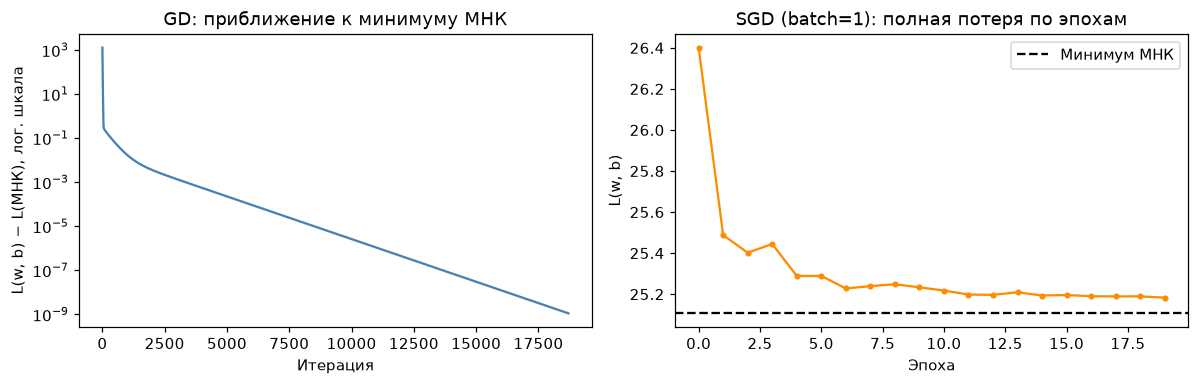

GD сошёлся за 18704 итераций; MSE на train совпадает с МНК.
При зависимых столбцах сравниваю прежде всего прогнозы и ошибку.


In [10]:
class BaselineEncoder:
    """Числовые столбцы и категории, известные только обучающей части."""
    def fit(self,frame):
        self.numeric_columns_ = list(NUM_COLS)
        self.categories_ = {c:sorted(frame[c].astype(str).unique()) for c in CAT_COLS}
        return self

    def transform(self,frame):
        blocks = [frame[self.numeric_columns_].to_numpy(float)]
        for column,levels in self.categories_.items():
            values = frame[column].astype(str).to_numpy()
            blocks.extend((values==level).astype(float)[:,None] for level in levels[1:])
        return np.column_stack(blocks)


tr_idx, va_idx = split_indices(len(y_all), test_size=0.2, seed=SEED)
base_encoder = BaselineEncoder().fit(train.iloc[tr_idx])
X_base_raw = base_encoder.transform(train)
scaler_base = ZScoreScaler().fit(X_base_raw[tr_idx])
X_tr, X_va = scaler_base.transform(X_base_raw[tr_idx]), scaler_base.transform(X_base_raw[va_idx])
y_tr, y_va = y_all[tr_idx], y_all[va_idx]

rank_X = np.linalg.matrix_rank(X_tr)
print(f'Размер X_tr: {X_tr.shape}, ранг матрицы: {rank_X} (есть линейно зависимые столбцы: {rank_X < X_tr.shape[1]})')

sk_lr = SkLinearRegression().fit(X_tr, y_tr)
sk_pred = sk_lr.predict(X_va)

m_an = LinearRegression(method='analytic').fit(X_tr, y_tr)
m_gd = LinearRegression(method='gd', lr=0.1, n_iter=50000, tol=1e-12).fit(X_tr, y_tr)
m_sgd = LinearRegression(method='sgd', lr=0.01, n_iter=20, batch_size=1, tol=1e-6, seed=SEED).fit(X_tr, y_tr)
sk_sgd = SkSGDRegressor(loss='squared_error', penalty=None, fit_intercept=True, max_iter=1000, tol=1e-4, random_state=SEED).fit(X_tr, y_tr)

rows = []
for name, model in [
    ('sklearn LinearRegression', sk_lr),
    ('Своя (analytic, lstsq)', m_an),
    ('Своя (gd)', m_gd),
    ('Своя (sgd, batch=1)', m_sgd),
    ('sklearn SGDRegressor (penalty=None)', sk_sgd),
]:
    pred = model.predict(X_va)
    m = all_metrics(y_va, pred)
    m['Откл. прогноза от sklearn LR'] = np.max(np.abs(pred - sk_pred))
    rows.append((name, m))

print(pd.DataFrame.from_dict(dict(rows), orient='index').round(6).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
optimal_loss = .5*mse(y_tr,m_an.predict(X_tr))
gd_gap = np.maximum(np.asarray(m_gd.loss_history_)-optimal_loss,np.finfo(float).eps)
ax[0].semilogy(gd_gap,color='steelblue')
ax[0].set(title='GD: приближение к минимуму МНК', xlabel='Итерация', ylabel='L(w, b) − L(МНК), лог. шкала')
ax[1].plot(m_sgd.loss_history_, color='darkorange', marker='o', markersize=3)
ax[1].axhline(optimal_loss,color='black',linestyle='--',label='Минимум МНК')
ax[1].set(title='SGD (batch=1): полная потеря по эпохам', xlabel='Эпоха', ylabel='L(w, b)')
ax[1].legend()
plt.tight_layout()
plt.show()
assert np.allclose(m_an.predict(X_va),sk_pred,atol=1e-8)
assert abs(mse(y_tr,m_gd.predict(X_tr))-mse(y_tr,m_an.predict(X_tr)))<1e-6
assert np.max(np.abs(m_gd.predict(X_va)-m_an.predict(X_va)))<.01
assert len(m_gd.loss_history_)<m_gd.n_iter
print('GD сошёлся за',len(m_gd.loss_history_),'итераций; MSE на train совпадает с МНК.')
print('При зависимых столбцах сравниваю прежде всего прогнозы и ошибку.')
unknown_frame = train.iloc[va_idx[:3]].copy()
unknown_frame[CAT_COLS] = 'Неизвестная категория'
assert np.isfinite(base_encoder.transform(unknown_frame)).all()


In [11]:
splits_103 = list(kfold_splits(103, k=5, shuffle=True, seed=SEED))
assert [len(v) for _, v in splits_103] == [21, 21, 21, 20, 20]
for tr_s, va_s in splits_103:
    assert len(set(tr_s) & set(va_s)) == 0
assert np.array_equal(np.sort(np.concatenate([v for _, v in splits_103])), np.arange(103))
assert all(np.array_equal(v1, v2) for (_, v1), (_, v2) in zip(splits_103, kfold_splits(103, k=5, shuffle=True, seed=SEED)))
print('Разбиение 103 строк на 5 фолдов прошло проверки.')

folds_mine = list(kfold_splits(len(y_all), k=5, shuffle=True, seed=SEED))
fold_rows = []
for fold_i, (tr_f, va_f) in enumerate(folds_mine):
    enc_f = BaselineEncoder().fit(train.iloc[tr_f])
    raw_tr_f,raw_va_f = enc_f.transform(train.iloc[tr_f]),enc_f.transform(train.iloc[va_f])
    sc_f = ZScoreScaler().fit(raw_tr_f)
    X_tr_f,X_va_f = sc_f.transform(raw_tr_f),sc_f.transform(raw_va_f)
    p_mine = LinearRegression(method='analytic').fit(X_tr_f, y_all[tr_f]).predict(X_va_f)
    p_sk = SkLinearRegression().fit(X_tr_f, y_all[tr_f]).predict(X_va_f)
    m_f = all_metrics(y_all[va_f], p_mine)
    m_f['Разница со sklearn'] = np.max(np.abs(p_mine - p_sk))
    assert m_f['Разница со sklearn']<1e-7
    fold_rows.append(m_f)

fold_df = pd.DataFrame(fold_rows, index=[f'Фолд {i+1}' for i in range(5)])
print(fold_df.round(5).to_string())
print('Среднее по фолдам:', fold_df[['MSE', 'MAE', 'R2', 'MAPE']].mean().round(4).to_dict())
print('Std по фолдам:    ', fold_df[['MSE', 'MAE', 'R2', 'MAPE']].std().round(4).to_dict())

Разбиение 103 строк на 5 фолдов прошло проверки.
             MSE      MAE       R2     MAPE  Разница со sklearn
Фолд 1  50.95225  5.71754  0.82713  0.13589                 0.0
Фолд 2  49.96629  5.66463  0.83349  0.13313                 0.0
Фолд 3  47.09111  5.53446  0.84128  0.12908                 0.0
Фолд 4  54.90365  5.95273  0.81285  0.14034                 0.0
Фолд 5  49.94006  5.70412  0.83437  0.13248                 0.0
Среднее по фолдам: {'MSE': 50.5707, 'MAE': 5.7147, 'R2': 0.8298, 'MAPE': 0.1342}
Std по фолдам:     {'MSE': 2.8192, 'MAE': 0.1515, 'R2': 0.0107, 'MAPE': 0.0042}


### Leave-one-out

В LOO каждый объект по очереди становится единственным валидационным. Для обычного МНК
со свободным членом можно получить те же прогнозы без полного переобучения на каждом шаге:

$$\hat y_i^{(-i)}=y_i-\frac{e_i}{1-h_{ii}},\qquad e_i=y_i-\hat y_i.$$

Здесь $h_{ii}$ — диагональ проектора на столбцы $X_a=[\mathbf1,X]$.
Вычисляю её через SVD, не формируя $X_a^\top X_a$.

Эту формулу использую только для базового МНК без регуляризации и отбора признаков.
Каждая категория встречается больше одного раза, поэтому удаление одной строки не меняет
набор категорий. Переобучение z-score также не меняет пространство прогнозов МНК
со свободным членом: меняются лишь масштабы и сдвиги столбцов. Проверяю ранг и условие
$h_{ii}<1$, чтобы удаление строки не приводило к потере ранга.

На 400 строках сравниваю формулу с прямыми переобучениями. В каждом из них заново обучаю
преобразования. После этой проверки считаю LOO для всей обучающей части — 7466 строк.
Метрики вычисляю по общему вектору прогнозов.


In [12]:
def loo_predictions_ols(X,y):
    a = np.column_stack([np.ones(len(X)),X])
    u,s,_ = np.linalg.svd(a,full_matrices=False)
    cutoff = np.finfo(float).eps*max(a.shape)*s[0]
    keep = s>cutoff
    u = u[:,keep]
    leverage = np.sum(u*u,axis=1)
    if np.min(1-leverage)<=1e-8:
        raise ValueError('LOO-формула неприменима: удаление строки может менять ранг')
    residual = y-u@(u.T@y)
    return y-residual/(1-leverage),int(keep.sum()),leverage

sub_n = 400
frame_tr = train.iloc[tr_idx].reset_index(drop=True)
frame_sub = frame_tr.iloc[:sub_n]
for frame in [frame_tr,frame_sub]:
    assert all(frame[c].value_counts().min()>1 for c in CAT_COLS)
X_sub,y_sub = X_tr[:sub_n],y_tr[:sub_n]
oof_sub_mine,oof_sub_sk = np.zeros(sub_n),np.zeros(sub_n)
for tr_i,va_i in leave_one_out_splits(sub_n):
    enc = BaselineEncoder().fit(frame_sub.iloc[tr_i])
    raw_tr,raw_va = enc.transform(frame_sub.iloc[tr_i]),enc.transform(frame_sub.iloc[va_i])
    sc = ZScoreScaler().fit(raw_tr)
    xx_tr,xx_va = sc.transform(raw_tr),sc.transform(raw_va)
    oof_sub_mine[va_i] = LinearRegression().fit(xx_tr,y_sub[tr_i]).predict(xx_va)
    oof_sub_sk[va_i] = SkLinearRegression().fit(xx_tr,y_sub[tr_i]).predict(xx_va)
oof_sub_fast,rank_sub,h_sub = loo_predictions_ols(X_sub,y_sub)
assert np.allclose(oof_sub_mine,oof_sub_sk,atol=1e-7,rtol=0)
assert np.allclose(oof_sub_mine,oof_sub_fast,atol=1e-7,rtol=0)
print(f'LOO на {sub_n} строках: max разница со sklearn {np.max(np.abs(oof_sub_mine-oof_sub_sk)):.2e}; '
      f'с формулой SVD {np.max(np.abs(oof_sub_mine-oof_sub_fast)):.2e}')
oof_full_loo,rank_full,h_full = loo_predictions_ols(X_tr,y_tr)
print(f'Полный LOO: n={len(y_tr)}, ранг={rank_full}/{X_tr.shape[1]+1}, min(1-h)={np.min(1-h_full):.4f}')
print('Метрики по всему OOF-вектору:',{k:round(v,4) for k,v in all_metrics(y_tr,oof_full_loo).items()})


LOO на 400 строках: max разница со sklearn 7.82e-11; с формулой SVD 3.14e-11
Полный LOO: n=7466, ранг=44/45, min(1-h)=0.8109
Метрики по всему OOF-вектору: {'MSE': 51.0895, 'MAE': 5.7396, 'R2': 0.8275, 'MAPE': 0.1348}


## 6. Регуляризация: L1, L2, L1+L2 и Lp

Во всех случаях минимизирую $\frac1{2n}\|Xw+b-y\|_2^2+\lambda R(w)$.
Меняется только штраф:

- **L2:** $R(w)=\frac12\sum_jw_j^2$, градиент штрафа — $\lambda w$.
- **L1:** $R(w)=\sum_j|w_j|$. В GD, SGD и координатном спуске использую мягкое порогование.
- **L1+L2:** $R(w)=\alpha\sum_j|w_j|+\frac{1-\alpha}{2}\sum_jw_j^2$,
  где `alpha` соответствует `l1_ratio` в своём классе.
- **Lp:** $R(w)=\sum_j(w_j^2+\varepsilon)^{p/2}$, где $\varepsilon=10^{-6}$.
  В этой реализации принимается конечное $p>0$. Сглаживание нужно для работы около нуля.
  При $p<1$ задача невыпуклая, поэтому результат может быть локальным минимумом.

Свободный член не штрафую. MSE в таблицах считаю отдельно, без штрафа.

Для сверки со sklearn беру `Ridge(alpha=n*lam)`, `Lasso(alpha=lam)` и
`ElasticNet(alpha=lam, l1_ratio=l1_ratio)`. Это соответствует выбранной функции потерь.
В аналитической ветке класса L1 и ElasticNet решаются координатным спуском, Lp — численно.

У Lp при $p=2$ нет множителя $1/2$, поэтому его `lam` соответствует L2 с `2*lam`.
При $p=1$ сглаженный штраф близок к L1. Обе связи проверяю ниже, затем смотрю,
как сила штрафа влияет на ошибку и величину коэффициентов.


In [13]:
lam_test = 0.25
reg_compare = []
for label, mine, gd_m, sk in [
    ('L2 (Ridge)',
     LinearRegression(method='analytic', penalty='l2', lam=lam_test),
     LinearRegression(method='gd', lr=0.1, n_iter=50000, tol=1e-12, penalty='l2', lam=lam_test),
     SkRidge(alpha=lam_test * len(y_tr))),
    ('L1 (Lasso)',
     LinearRegression(method='analytic', penalty='l1', lam=lam_test),
     LinearRegression(method='gd', lr=0.1, n_iter=50000, tol=1e-12, penalty='l1', lam=lam_test),
     SkLasso(alpha=lam_test, tol=1e-10, max_iter=200000)),
    ('L1+L2 (ElasticNet)',
     LinearRegression(method='analytic', penalty='elasticnet', lam=lam_test, l1_ratio=0.5),
     LinearRegression(method='gd', lr=0.1, n_iter=50000, tol=1e-12, penalty='elasticnet', lam=lam_test, l1_ratio=0.5),
     SkElasticNet(alpha=lam_test, l1_ratio=0.5, tol=1e-10, max_iter=200000)),
]:
    mine.fit(X_tr, y_tr)
    gd_m.fit(X_tr, y_tr)
    sk.fit(X_tr, y_tr)
    assert np.max(np.abs(mine.predict(X_va)-sk.predict(X_va)))<1e-5
    assert abs(mse(y_va,gd_m.predict(X_va))-mse(y_va,mine.predict(X_va)))<1e-3
    reg_compare.append({
        'Модель': label,
        'MSE (analytic/CD)': round(mse(y_va, mine.predict(X_va)), 4),
        'MSE (GD)': round(mse(y_va, gd_m.predict(X_va)), 4),
        'MSE (sklearn)': round(mse(y_va, sk.predict(X_va)), 4),
        'Разница весов со sklearn': float(np.max(np.abs(mine.coef_ - sk.coef_))),
    })
print(pd.DataFrame(reg_compare).to_string(index=False))

lp_1 = LinearRegression(method='analytic', penalty='lp', lam=0.25, p=1.0).fit(X_tr, y_tr)
l1_ref = LinearRegression(method='analytic', penalty='l1', lam=0.25).fit(X_tr, y_tr)
lp_2 = LinearRegression(method='analytic', penalty='lp', lam=0.125, p=2.0).fit(X_tr, y_tr)
l2_ref = LinearRegression(method='analytic', penalty='l2', lam=0.25).fit(X_tr, y_tr)
print(f'Связь Lp с L1/L2: макс. откл. Lp(p=1, lam=0.25) от L1 = {np.max(np.abs(lp_1.coef_ - l1_ref.coef_)):.4f} | '
      f'Lp(p=2, lam=0.125) от L2(lam=0.25) = {np.max(np.abs(lp_2.coef_ - l2_ref.coef_)):.2e}')
assert np.max(np.abs(lp_2.coef_-l2_ref.coef_))<1e-3
def l1_objective(model):
    return .5*mse(y_tr,model.predict(X_tr))+.25*np.abs(model.coef_).sum()
smoothing_bound = .25*len(lp_1.coef_)*np.sqrt(1e-6)
assert l1_objective(lp_1)-l1_objective(l1_ref)<=smoothing_bound+1e-4
print('Проверки Lp при p=1 и p=2 пройдены.')


            Модель  MSE (analytic/CD)  MSE (GD)  MSE (sklearn)  Разница весов со sklearn
        L2 (Ridge)            52.2586   52.2586        52.2586              8.633372e-14
        L1 (Lasso)            50.8203   50.8203        50.8203              1.117686e-08
L1+L2 (ElasticNet)            51.3610   51.3610        51.3610              2.018937e-09


Связь Lp с L1/L2: макс. откл. Lp(p=1, lam=0.25) от L1 = 0.0178 | Lp(p=2, lam=0.125) от L2(lam=0.25) = 2.11e-04
Проверки Lp при p=1 и p=2 пройдены.


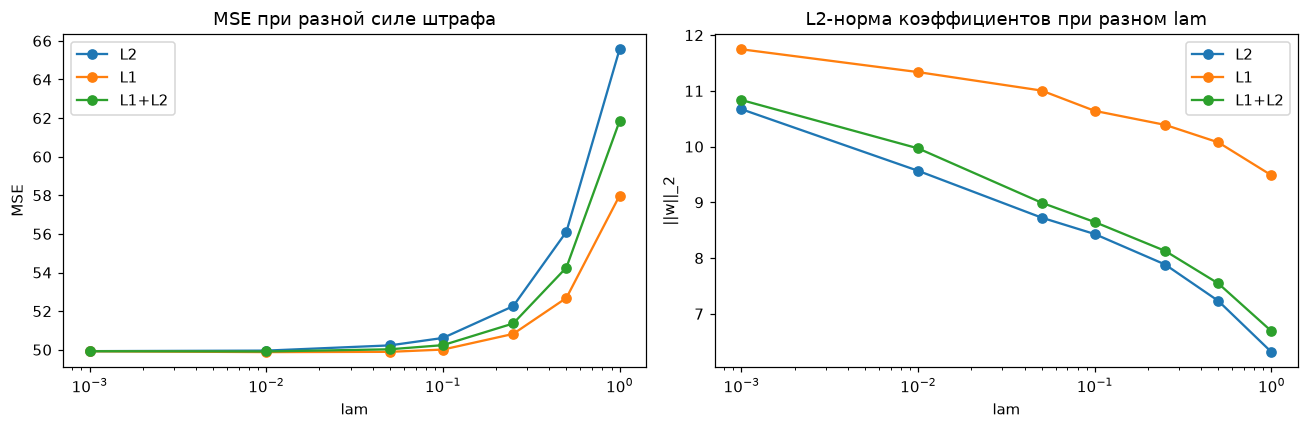

Lp-регуляризация при разных p:
  p     MSE  L2-норма весов  Сошёлся
0.5 49.8480         10.6118     True
1.0 49.8937         10.5510     True
1.5 50.0762          9.0470     True
2.0 50.6106          8.4300     True
3.0 54.3216          7.6265     True


In [14]:
alphas = [0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for pen, title in [('l2', 'L2'), ('l1', 'L1'), ('elasticnet', 'L1+L2')]:
    mses, norms = [], []
    for a in alphas:
        mdl = LinearRegression(method='analytic', penalty=pen, lam=a).fit(X_tr, y_tr)
        mses.append(mse(y_va, mdl.predict(X_va)))
        norms.append(float(np.linalg.norm(mdl.coef_)))
    ax[0].plot(alphas, mses, marker='o', label=title)
    ax[1].plot(alphas, norms, marker='o', label=title)
ax[0].set_xscale('log')
ax[0].set(title='MSE при разной силе штрафа', xlabel='lam', ylabel='MSE')
ax[0].legend()
ax[1].set_xscale('log')
ax[1].set(title='L2-норма коэффициентов при разном lam', xlabel='lam', ylabel='||w||_2')
ax[1].legend()
plt.tight_layout()
plt.show()

lp_rows = []
for p_val in [0.5, 1.0, 1.5, 2.0, 3.0]:
    m_lp = LinearRegression(method='analytic', penalty='lp', lam=0.05, p=p_val).fit(X_tr, y_tr)
    assert m_lp.opt_success_
    lp_rows.append({'p': p_val, 'MSE': mse(y_va, m_lp.predict(X_va)), 'L2-норма весов': float(np.linalg.norm(m_lp.coef_)), 'Сошёлся': m_lp.opt_success_})
print('Lp-регуляризация при разных p:')
print(pd.DataFrame(lp_rows).round(4).to_string(index=False))

## 7. Итоговая модель для Kaggle

МНК на исходных признаках даёт MSE около 50. Чтобы учесть два уровня риска и пороговые
зависимости, использую скоринговую карту $S(x)$ и индекс верхнего режима $P(x)$:

$$\hat y(x)=S(x)(1+\kappa P(x)),\qquad
P(x)=\mathrm{clip}(w_0+w^\top g(x),0,1).$$

Карта складывается из индикаторов вида `CreditScore >= 600` и нескольких бинарных признаков.
Индекс оценивается линейной регрессией и ограничивается отрезком от 0 до 1.
Коэффициенты карты, множитель $\kappa$ и принадлежность к режимам уточняются на обучающих
строках. При предсказании используется только набор признаков заёмщика.

Пороги и настройки этой модели зафиксированы. Ниже проверяю её на пяти фолдах:
в каждом заново обучаются карта, индекс и нормализация.


In [15]:
SCORECARD = {
    'AnnualIncome': [30000, 50000, 80000, 120000],
    'CreditCardUtilizationRate': [0.2, 0.4, 0.6],
    'CreditScore': [600, 650, 700, 750],
    'DebtToIncomeRatio': [0.2, 0.3, 0.4, 0.5],
    'LengthOfCreditHistory': [3, 5, 7, 10],
    'NetWorth': [50000, 100000, 250000, 500000, 1000000],
}

BAND_COLUMNS = [
    'CreditScore', 'MonthlyIncome', 'TotalDebtToIncomeRatio', 'LoanAmount', 'InterestRate',
    'BankruptcyHistory', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory',
    'NetWorth', 'Age', 'Experience'
]


def scorecard_features(df):
    cols = {f'{col}>={t:g}': (df[col].to_numpy(float) >= t).astype(float) for col, grid in SCORECARD.items() for t in grid}
    cols['BankruptcyHistory'] = df['BankruptcyHistory'].to_numpy(float)
    cols['PreviousLoanDefaults'] = df['PreviousLoanDefaults'].to_numpy(float)
    cols['Employed'] = (df['EmploymentStatus'] == 'Employed').to_numpy(float)
    return pd.DataFrame(cols, index=df.index)


def band_features(df, age_knots=(30, 40, 50, 60)):
    d = df[BAND_COLUMNS].astype(float).copy()
    d['Unemployed'] = (df['EmploymentStatus'] == 'Unemployed').astype(float)
    d['OwnOrMortgage'] = df['HomeOwnershipStatus'].isin(['Own', 'Mortgage']).astype(float)
    for level in ['Associate', 'Bachelor', 'Master', 'Doctorate']:
        d['Education=' + level] = (df['EducationLevel'] == level).astype(float)
    for knot in age_knots:
        d[f'Age>{knot}'] = np.maximum(df['Age'].astype(float) - knot, 0.0)
    return d


class ScorecardMixtureRegression:
    def __init__(self, near_iters=4, age_knots=(30, 40, 50, 60), kappa0=0.36, max_em_iter=25, lam_index=1e-3):
        self.near_iters = near_iters
        self.age_knots = age_knots
        self.kappa0 = kappa0
        self.max_em_iter = max_em_iter
        self.lam_index = lam_index

    def _fit_score(self, A, y):
        kappa, labels = self.kappa0, None
        ols = LinearRegression(method='analytic', fit_intercept=False)
        w = ols.fit(A, y / (1.0 + kappa * (y > np.median(y)))).coef_
        for _ in range(self.max_em_iter):
            S = A @ w
            new_labels = (np.abs(y - S * (1.0 + kappa)) < np.abs(y - S)).astype(float)
            if labels is not None and (new_labels == labels).all():
                break
            labels = new_labels
            for _ in range(3):
                w = ols.fit(A * (1.0 + kappa * labels)[:, None], y).coef_
                S = A @ w
                kappa = LinearRegression(method='analytic', fit_intercept=False).fit((labels * S)[:, None], y - S).coef_[0]
        return w, kappa, labels

    def _fit_index(self, X, r):
        fit_fn = lambda Xp, rp: LinearRegression(method='analytic', penalty='l2', lam=self.lam_index).fit(Xp, rp)
        model = fit_fn(X, r)
        for _ in range(self.near_iters):
            u = model.predict(X)
            near = (u > 0.1) & (u < 0.9)
            model = fit_fn(X[near], r[near])
        return model

    def _fit_score_soft(self, A, y, X, w, kappa, labels, n_rounds=4, n_steps=10):
        ols = LinearRegression(method='analytic', fit_intercept=False)
        sigma2 = np.mean((y - (A @ w) * (1.0 + kappa * labels)) ** 2)
        prior = np.full(len(y), 0.5)
        for _ in range(n_rounds):
            for _ in range(n_steps):
                S = A @ w
                log_ratio = ((y - S) ** 2 - (y - S * (1.0 + kappa)) ** 2) / (2.0 * sigma2)
                r = prior / (prior + (1.0 - prior) * np.exp(-np.clip(log_ratio, -500.0, 500.0)))
                root_r, root_q = np.sqrt(r)[:, None], np.sqrt(1.0 - r)[:, None]
                design = np.vstack([A * (1.0 + kappa) * root_r, A * root_q])
                target = np.concatenate([y * root_r[:, 0], y * root_q[:, 0]])
                w = ols.fit(design, target).coef_
                S = A @ w
                kappa = np.sum(r * S * (y - S)) / np.sum(r * S * S)
                sigma2 = np.mean(r * (y - S * (1.0 + kappa)) ** 2 + (1.0 - r) * (y - S) ** 2)
            prior = np.clip(self._fit_index(X, r).predict(X), 1e-3, 1.0 - 1e-3)
        return w, kappa, r

    def fit(self, df, y):
        y = np.asarray(y, dtype=float)
        A = np.column_stack([np.ones(len(y)), scorecard_features(df).to_numpy()])
        self.band_scaler_ = ZScoreScaler()
        X = self.band_scaler_.fit_transform(band_features(df, self.age_knots).to_numpy())
        self.w_, self.kappa_, self.labels_ = self._fit_score(A, y)
        self.w_, self.kappa_, self.responsibilities_ = self._fit_score_soft(A, y, X, self.w_, self.kappa_, self.labels_)
        self.labels_ = (self.responsibilities_ > 0.5).astype(float)
        self.index_ = self._fit_index(X, self.responsibilities_)
        return self

    def score(self, df):
        return np.column_stack([np.ones(len(df)), scorecard_features(df).to_numpy()]) @ self.w_

    def band_probability(self, df):
        X = self.band_scaler_.transform(band_features(df, self.age_knots).to_numpy())
        return np.clip(self.index_.predict(X), 0.0, 1.0)

    def predict(self, df):
        return self.score(df) * (1.0 + self.kappa_ * self.band_probability(df))

In [16]:
oof_final = np.zeros(len(y_all))
fold_mses = []
for tr_i, va_i in kfold_splits(len(y_all), k=5, shuffle=True, seed=SEED):
    m = ScorecardMixtureRegression().fit(train.iloc[tr_i], y_all[tr_i])
    oof_final[va_i] = m.predict(train.iloc[va_i])
    fold_mses.append(mse(y_all[va_i], oof_final[va_i]))

cv_metrics = all_metrics(y_all, oof_final)
print('Локальный 5-fold CV итоговой модели:', {k: round(v, 4) for k, v in cv_metrics.items()})
print('MSE по фолдам:', [round(x, 4) for x in fold_mses])
print('Среднее MSE по фолдам:',round(float(np.mean(fold_mses)),4),
      '| стандартное отклонение:',round(float(np.std(fold_mses,ddof=1)),4))


Локальный 5-fold CV итоговой модели: {'MSE': 18.1747, 'MAE': 2.9583, 'R2': 0.9389, 'MAPE': 0.0685}
MSE по фолдам: [17.693, 17.9901, 18.0917, 19.5172, 17.582]
Среднее MSE по фолдам: 18.1748 | стандартное отклонение: 0.7789


## 8. Финальное обучение и файл посылки

Обучаю выбранную модель на всех 9332 полных строках train и получаю прогноз для test.
В файл записываю `ID` из исходной таблицы и соответствующий `RiskScore`.
Предсказания не округляю и не ограничиваю по диапазону.

Если рядом уже есть `submission.csv`, сначала проверяю, что его значения совпадают
с повторным расчётом. В этом случае сохраняю готовый файл без перезаписи.


Предсказания совпали с готовым CSV. Файл оставлен без изменений.


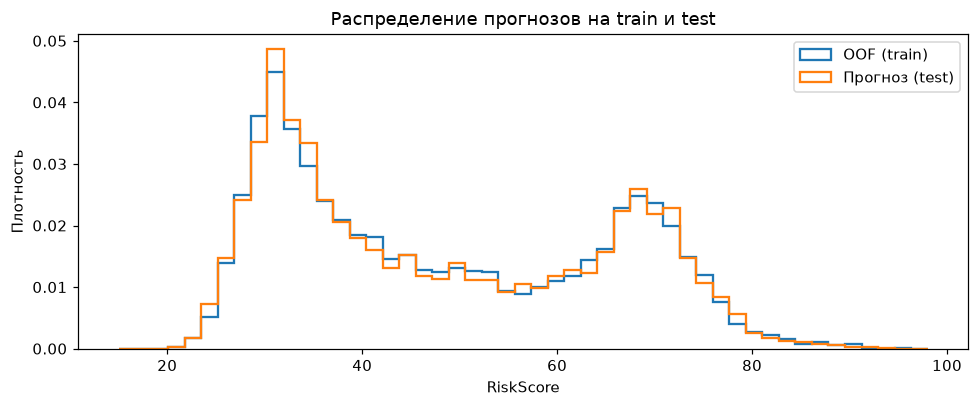

submission.csv: (5000, 2), пропусков 0
 ID  RiskScore
  0  32.925334
  1  53.425524
  2  30.019134
  3  34.912057
  4  33.018581
Максимальное расхождение CSV с повторным прогнозом: 1.8474111129762605e-13


In [17]:
final_model = ScorecardMixtureRegression().fit(train,y_all)
test_pred = final_model.predict(test)
assert test_pred.shape==(len(test),) and np.isfinite(test_pred).all()
submission = pd.DataFrame({'ID':test['ID'].to_numpy(),TARGET:test_pred})
sub_path = OUT_DIR/'submission.csv'

if sub_path.exists():
    saved = pd.read_csv(sub_path)
    assert list(saved.columns)==['ID','RiskScore'] and len(saved)==len(test)
    assert saved.ID.equals(test.ID) and pd.api.types.is_numeric_dtype(saved[TARGET])
    assert np.isfinite(saved[TARGET]).all()
    if not np.allclose(saved[TARGET].to_numpy(),test_pred,atol=1e-10,rtol=0):
        raise ValueError('Существующий submission.csv отличается от прогноза: сохраните его отдельно перед новым запуском')
    print('Предсказания совпали с готовым CSV. Файл оставлен без изменений.')
else:
    submission.to_csv(sub_path,index=False)
    saved = pd.read_csv(sub_path)

assert list(saved.columns)==['ID','RiskScore']
assert saved.ID.equals(sample.ID) and saved.ID.equals(test.ID) and saved.ID.is_unique
assert saved.shape==sample.shape==(len(test),2)
assert np.isfinite(saved[TARGET]).all() and not saved.isna().any().any()
assert np.allclose(saved[TARGET].to_numpy(),test_pred,atol=1e-10,rtol=0)

fig,ax = plt.subplots(figsize=(9,3.8))
bins = np.linspace(15,98,50)
ax.hist(oof_final,bins=bins,density=True,histtype='step',linewidth=1.5,label='OOF (train)')
ax.hist(test_pred,bins=bins,density=True,histtype='step',linewidth=1.5,label='Прогноз (test)')
ax.set(title='Распределение прогнозов на train и test',xlabel='RiskScore',ylabel='Плотность')
ax.legend();plt.tight_layout();plt.show()
print(f'submission.csv: {saved.shape}, пропусков {int(saved.isna().sum().sum())}')
print(saved.head().to_string(index=False))
print('Максимальное расхождение CSV с повторным прогнозом:',float(np.max(np.abs(saved[TARGET]-test_pred))))


### Выполненные задания

| Задание | Баллы | Раздел ноутбука |
|---|---|---|
| EDA (графики признаков, таргета, матрица корреляций, выводы) | 1 | Разделы 1–2 |
| Нормализация `z-score` и `min-max` (обучение на train, константный столбец, сверка) | 1 | Раздел 3 |
| Метрики `MSE`, `MAE`, `R²`, `MAPE` (формулы, краевые случаи, сверка со `sklearn`) | 2 | Раздел 4 |
| `LinearRegression` (`analytic`, `gd`, `sgd`), `tol`, проверки, сходимость, `SGDRegressor` | 3 | Раздел 5 |
| Кросс-валидация `k-fold` и `leave-one-out` (подвыборка 400 + полный LOO через SVD) | 3 | Раздел 5 |
| Доп.: регуляризации `L1`, `L2`, `L1+L2` и проверка согласованности | +2 | Раздел 6 |
| Доп.: `Lp`-регуляризация с параметром `p` и проверкой сходимости | +1 | Раздел 6 |
| Итоговая модель `ScorecardMixtureRegression` и `submission.csv` | Допуск | Разделы 7–8 |

In [18]:
summary = pd.DataFrame({
    'Итоговая модель, 5-fold, все полные строки':cv_metrics,
    'Базовый МНК, LOO на обучающей части':all_metrics(y_tr,oof_full_loo),
}).T
print('Локальные оценки; MAPE — доля:')
display(summary)


Локальные оценки; MAPE — доля:


,MSE,MAE,R2,MAPE
"Итоговая модель, 5-fold, все полные строки",18.174732,2.958315,0.938866,0.068543
"Базовый МНК, LOO на обучающей части",51.089505,5.739603,0.827536,0.134811


### Выводы

Итоговая модель дала локальный 5-fold MSE около 18,17 против примерно 50 у МНК
на исходных признаках. Основное изменение — скоринговая карта и учёт двух режимов риска.

Аналитическое решение совпало со sklearn. GD сошёлся к тому же минимуму,
а SGD даёт одинаковый результат при повторном запуске с тем же seed.
Регуляризация уменьшает веса; L1 и совместный штраф могут занулять часть коэффициентов.
Связь Lp с L1 и L2 проверена с учётом сглаживания и масштаба штрафа.

LOO рассчитан для базового МНК на 7466 строках. Это другая модель и другой размер
обучающей выборки, поэтому его ошибку нельзя напрямую сравнивать с CV итоговой модели
на 9332 строках. Выбор решения опирался на локальные проверки; ошибка на тестовой выборке
оценивается отдельно на Kaggle.

В конце проверены число строк, порядок ID, отсутствие пропусков и повторяемость предсказаний.
Данные test при обучении не использовались.
